# Testes estatísticos (fonte única para o texto do TCC)

Este é o **único** notebook que implementa testes estatísticos. Ele gera **apenas** os artefatos usados no texto (Seção *Análise Estatística* do capítulo de Resultados):

- `tex/tabela_testes_estatisticos.tex`: tabela da comparação par a par;
- `img/testes_estatisticos.{pdf,png}` (também copiada para `Texto/Imagens/`): representação visual dos testes.

**Escopo:** apenas os métodos competitivos, AisleBased, ILS-VND e Santos e Baldotto (2025). O OrderBased fica fora porque é dominado por todos os demais em 49 das 50 instâncias; incluí-lo só acrescentaria comparações de resultado já evidente e aumentaria a correção de Holm.

Os valores citados no parágrafo do texto (rankings médios, estatística de Friedman e análise de sensibilidade) são impressos nas células abaixo.

**Decisões de protocolo**

1. **Unidade de análise = instância.** Cada algoritmo é representado, em cada instância, pela média das 30 sementes. Tratar as 1.500 execuções como observações independentes seria pseudorreplicação, já que OrderBased e AisleBased são determinísticos.
2. **Escala normalizada (RPD).** O Wilcoxon ordena as magnitudes das diferenças **entre instâncias**. O valor bruto da função objetivo varia de 2 a 1.633 conforme a instância, então as diferenças só são comparáveis na escala relativa do RPD.
3. **Empates por tolerância.** Diferenças relativas ≤ `TOL` = 0,01% são tratadas como empate, a mesma tolerância de #MSC e da dominância.
4. **Teste global:** Friedman com correção para empates (Demšar, 2006). A estatística F de Iman–Davenport é impressa apenas como conferência.
5. **Comparações par a par:** Wilcoxon pareado nos 3 pares, com ajuste de Holm. Esse procedimento é preferido aos pós-testes baseados em ranking médio (Benavoli; Corani; Mangili, 2016), porque o resultado de um par não depende dos demais algoritmos incluídos.
6. **Tamanho de efeito:** correlação rank-bisserial pareada, $r_{rb} \in [-1, 1]$.
7. **Sensibilidade:** o Wilcoxon é recalculado com os três tratamentos de diferenças nulas do SciPy (`wilcox`, `pratt` e `zsplit`).

In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Image, display
import pandas as pd
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks" / "utils" / "__init__.py").exists())
RESULTS = ROOT / "project" / "results"
BEST_CSV = ROOT / "best_solutions" / "best_objectives.csv"
TEX = ROOT / "notebooks" / "resultados" / "tex"; TEX.mkdir(parents=True, exist_ok=True)
IMG = ROOT / "notebooks" / "resultados" / "img"; IMG.mkdir(parents=True, exist_ok=True)
TEXTO_IMG = ROOT.parent / "Texto" / "Imagens"

DATASETS = ["a", "b", "x"]
# Apenas os métodos competitivos (OrderBased excluído; ver escopo acima)
ALGOS = {"aisle_based": "AisleBased", "ils_vnd_all": "ILS-VND", "andre_feijo_all": "Santos e Baldotto (2025)"}
# Mesmas cores das demais figuras do texto (figuras_texto_tcc.ipynb)
COR = {"AisleBased": "#1f77b4", "ILS-VND": "#d62728", "Santos e Baldotto (2025)": "#2ca02c"}
NOMES = list(ALGOS.values())
TOL = 1e-4      # 0,01 %, mesma tolerância de #MSC e da dominância
ALPHA = 0.05
ZERO_METHOD = "wilcox"   # tratamento principal das diferenças nulas (descartadas)

frames = []
for pasta, nome in ALGOS.items():
    for ds in DATASETS:
        for f in sorted((RESULTS / pasta / ds).glob("instance_*.csv")):
            d = pd.read_csv(f, usecols=["objective"])
            d["algo"], d["dataset"], d["instance"] = nome, ds, f.stem + ".txt"
            frames.append(d)
raw = pd.concat(frames, ignore_index=True).merge(pd.read_csv(BEST_CSV), on=["dataset", "instance"], how="left")
assert raw.best_objective.notna().all()
raw["rpd"] = (raw.best_objective - raw.objective) / raw.best_objective * 100

g = raw.groupby(["dataset", "instance", "algo"])
assert (g.size() == 30).all(), "esperadas 30 sementes por instância e algoritmo"
OBJ = g.objective.mean().unstack()[NOMES]
RPD = g.rpd.mean().unstack()[NOMES]
N, K = OBJ.shape
print(f"N = {N} instâncias, k = {K} algoritmos")

N = 50 instâncias, k = 3 algoritmos


In [2]:
def empate(a, b):
    # Empate quando a diferença relativa (sobre o objetivo médio) é <= TOL.
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.abs(a - b) <= TOL * np.maximum(np.abs(a), np.abs(b))

def ranks_instancia(v):
    # Ranking por instância (1 = maior objetivo); empates por tolerância recebem o ranking médio.
    v = np.asarray(v, float)
    r = np.empty(len(v))
    for i in range(len(v)):
        tie = empate(v, v[i]); tie[i] = False
        r[i] = 1 + ((v > v[i]) & ~tie).sum() + 0.5 * tie.sum()
    return r

def friedman(M):
    # Friedman com correção de empates + Iman-Davenport. M: (N, k), maior = melhor.
    R = np.array([ranks_instancia(x) for x in np.asarray(M, float)])
    n, k = R.shape
    # A tolerância não é transitiva: confere que os rankings de cada instância somam k(k+1)/2.
    assert np.allclose(R.sum(1), k * (k + 1) / 2), "ranking inconsistente em alguma instância"
    Rj = R.mean(0)
    chi2 = 12 * n / (k * (k + 1)) * (np.sum(Rj ** 2) - k * (k + 1) ** 2 / 4)
    t = sum(np.sum(c ** 3 - c) for c in (np.unique(r, return_counts=True)[1] for r in R))
    chi2_c = chi2 / (1 - t / (n * k * (k ** 2 - 1)))
    p_chi2 = stats.chi2.sf(chi2_c, k - 1)
    f_id = (n - 1) * chi2_c / (n * (k - 1) - chi2_c)
    p_f = stats.f.sf(f_id, k - 1, (k - 1) * (n - 1))
    return pd.Series(Rj, index=M.columns), chi2_c, p_chi2, f_id, p_f

def holm(p):
    # Ajuste de Holm (step-down) para um dict {chave: p}.
    chaves = sorted(p, key=p.get); m = len(chaves); out = {}; acc = 0.0
    for i, c in enumerate(chaves):
        acc = max(acc, min(1.0, (m - i) * p[c])); out[c] = acc
    return out

def diferencas_rpd(a, b):
    # Diferença pareada RPD(b) - RPD(a) por instância (> 0: a melhor), zerada nos empates.
    d = (RPD[b] - RPD[a]).to_numpy()
    return np.where(empate(OBJ[a], OBJ[b]), 0.0, d)

def rank_bisserial(d):
    # Correlação rank-bisserial pareada sobre as diferenças não nulas.
    d = d[d != 0]
    if d.size == 0:
        return 0.0
    r = stats.rankdata(np.abs(d))
    return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()

# --- Verificações da implementação ---
# 1) Sem tolerância e sem empates, o Friedman manual coincide com o SciPy.
_M = np.random.default_rng(0).normal(size=(30, 4))
_, _c, _p, _, _ = friedman(pd.DataFrame(_M))
_s = stats.friedmanchisquare(*(-_M).T)
assert np.isclose(_c, _s.statistic) and np.isclose(_p, _s.pvalue)
# 2) Com empates exatos, a correção de empates coincide com o SciPy.
_M2 = np.round(_M, 0)
_, _c2, _, _, _ = friedman(pd.DataFrame(_M2))
_save = TOL; TOL = 0.0
_, _c3, _, _, _ = friedman(pd.DataFrame(_M2)); TOL = _save
assert np.isclose(_c3, stats.friedmanchisquare(*(-_M2).T).statistic)
# 3) Holm conhecido: p = (0,01; 0,04; 0,03) -> (0,03; 0,06; 0,06).
assert np.allclose([holm({1: .01, 2: .04, 3: .03})[k] for k in (1, 2, 3)], [.03, .06, .06])
print("verificações OK")

verificações OK


In [3]:
rank_medio, chi2_f, p_chi2, f_id, p_f = friedman(OBJ)
rank_medio = rank_medio.sort_values()
print("Ranking médio de Friedman (1 = melhor):")
print(rank_medio.round(2).to_string())
print(f"\nFriedman (corrigido para empates): chi2_F({K-1}) = {chi2_f:.2f}, p = {p_chi2:.2e}")
print(f"Iman-Davenport: F({K-1}, {(K-1)*(N-1)}) = {f_id:.2f}, p = {p_f:.2e}")

Ranking médio de Friedman (1 = melhor):
algo
Santos e Baldotto (2025)    1.58
ILS-VND                     1.75
AisleBased                  2.67

Friedman (corrigido para empates): chi2_F(2) = 57.32, p = 3.58e-13
Iman-Davenport: F(2, 98) = 65.80, p = 7.63e-19


In [4]:
ordem = list(rank_medio.index)                      # melhor ranking primeiro
pares = [(a, b) for a, b in combinations(ordem, 2)]  # a = melhor ranqueado do par

linhas, p_bruto = [], {}
for a, b in pares:
    d = diferencas_rpd(a, b)
    nz = d[d != 0]
    p_bruto[(a, b)] = stats.wilcoxon(d, zero_method=ZERO_METHOD).pvalue if nz.size else 1.0
    linhas.append({"A": a, "B": b, "n_dif": nz.size, "vit_A": int((nz > 0).sum()), "vit_B": int((nz < 0).sum()),
                   "dif_media_pp": d.mean(), "r_rb": rank_bisserial(d),
                   **{f"p_{zm}": (stats.wilcoxon(d, zero_method=zm).pvalue if nz.size else 1.0)
                      for zm in ("wilcox", "pratt", "zsplit")}})
p_holm = holm(p_bruto)
tab = pd.DataFrame(linhas)
tab["p_holm"] = [p_holm[(a, b)] for a, b in pares]
tab["signif"] = tab.p_holm < ALPHA
pd.set_option("display.width", 200)
print(tab.round(4).to_string(index=False))

                       A          B  n_dif  vit_A  vit_B  dif_media_pp   r_rb  p_wilcox  p_pratt  p_zsplit  p_holm  signif
Santos e Baldotto (2025)    ILS-VND     18     13      5        0.1624 0.5789    0.0311   0.0454    0.0766  0.0311    True
Santos e Baldotto (2025) AisleBased     34     34      0        3.6815 1.0000    0.0000   0.0000    0.0000  0.0000    True
                 ILS-VND AisleBased     33     33      0        3.5190 1.0000    0.0000   0.0000    0.0000  0.0000    True


In [5]:
def num(v, casas=2):
    return f"{v:.{casas}f}".replace(".", "{,}")

def p_tex(v):
    return r"$<0{,}001$" if v < 1e-3 else f"${num(v, 3)}$"

def nome_curto(a):
    return "Santos e Baldotto" if a.startswith("Santos") else a

L = [r"\begin{table}[htbp]",
     r"  \centering",
     rf"  \caption{{\label{{tab:testes_estatisticos}} Comparação par a par pelo teste de Wilcoxon pareado sobre o RPD médio por instância ($N = {N}$), com ajuste de Holm. Teste global de Friedman, corrigido para empates: $\chi^2_F({K-1}) = {num(chi2_f)}$, $p < 0{{,}}001$.}}",
     r"  \resizebox{\textwidth}{!}{",
     r"    \begin{tabular}{l r r r r}",
     r"      \toprule",
     r"      \textbf{Comparação (A $\times$ B)} & \textbf{Instâncias com diferença} & \textbf{Vitórias A / B} & \textbf{$r_{rb}$} & \textbf{$p$ (Holm)} \\",
     r"      \midrule"]
for _, r in tab.iterrows():
    L.append(rf"      {nome_curto(r.A)} $\times$ {nome_curto(r.B)} & {r.n_dif} & {r.vit_A} / {r.vit_B} & ${num(r.r_rb)}$ & {p_tex(r.p_holm)} \\")
L += [r"      \bottomrule",
      r"    \end{tabular}",
      r"  }",
      r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026. Em cada par, A é o algoritmo de melhor ranking médio de Friedman; $r_{rb} > 0$ favorece A. Diferenças relativas de até 0,01\% no objetivo são tratadas como empate e não entram no teste.}",
      r"\end{table}"]
(TEX / "tabela_testes_estatisticos.tex").write_text("\n".join(L) + "\n", encoding="utf-8")
print("\n".join(L))

\begin{table}[htbp]
  \centering
  \caption{\label{tab:testes_estatisticos} Comparação par a par pelo teste de Wilcoxon pareado sobre o RPD médio por instância ($N = 50$), com ajuste de Holm. Teste global de Friedman, corrigido para empates: $\chi^2_F(2) = 57{,}32$, $p < 0{,}001$.}
  \resizebox{\textwidth}{!}{
    \begin{tabular}{l r r r r}
      \toprule
      \textbf{Comparação (A $\times$ B)} & \textbf{Instâncias com diferença} & \textbf{Vitórias A / B} & \textbf{$r_{rb}$} & \textbf{$p$ (Holm)} \\
      \midrule
      Santos e Baldotto $\times$ ILS-VND & 18 & 13 / 5 & $0{,}58$ & $0{,}031$ \\
      Santos e Baldotto $\times$ AisleBased & 34 & 34 / 0 & $1{,}00$ & $<0{,}001$ \\
      ILS-VND $\times$ AisleBased & 33 & 33 / 0 & $1{,}00$ & $<0{,}001$ \\
      \bottomrule
    \end{tabular}
  }
  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026. Em cada par, A é o algoritmo de melhor ranking médio de Friedman; $r_{rb} > 0$ favorece A. Diferenças relativas de até 0,01\% no objetivo

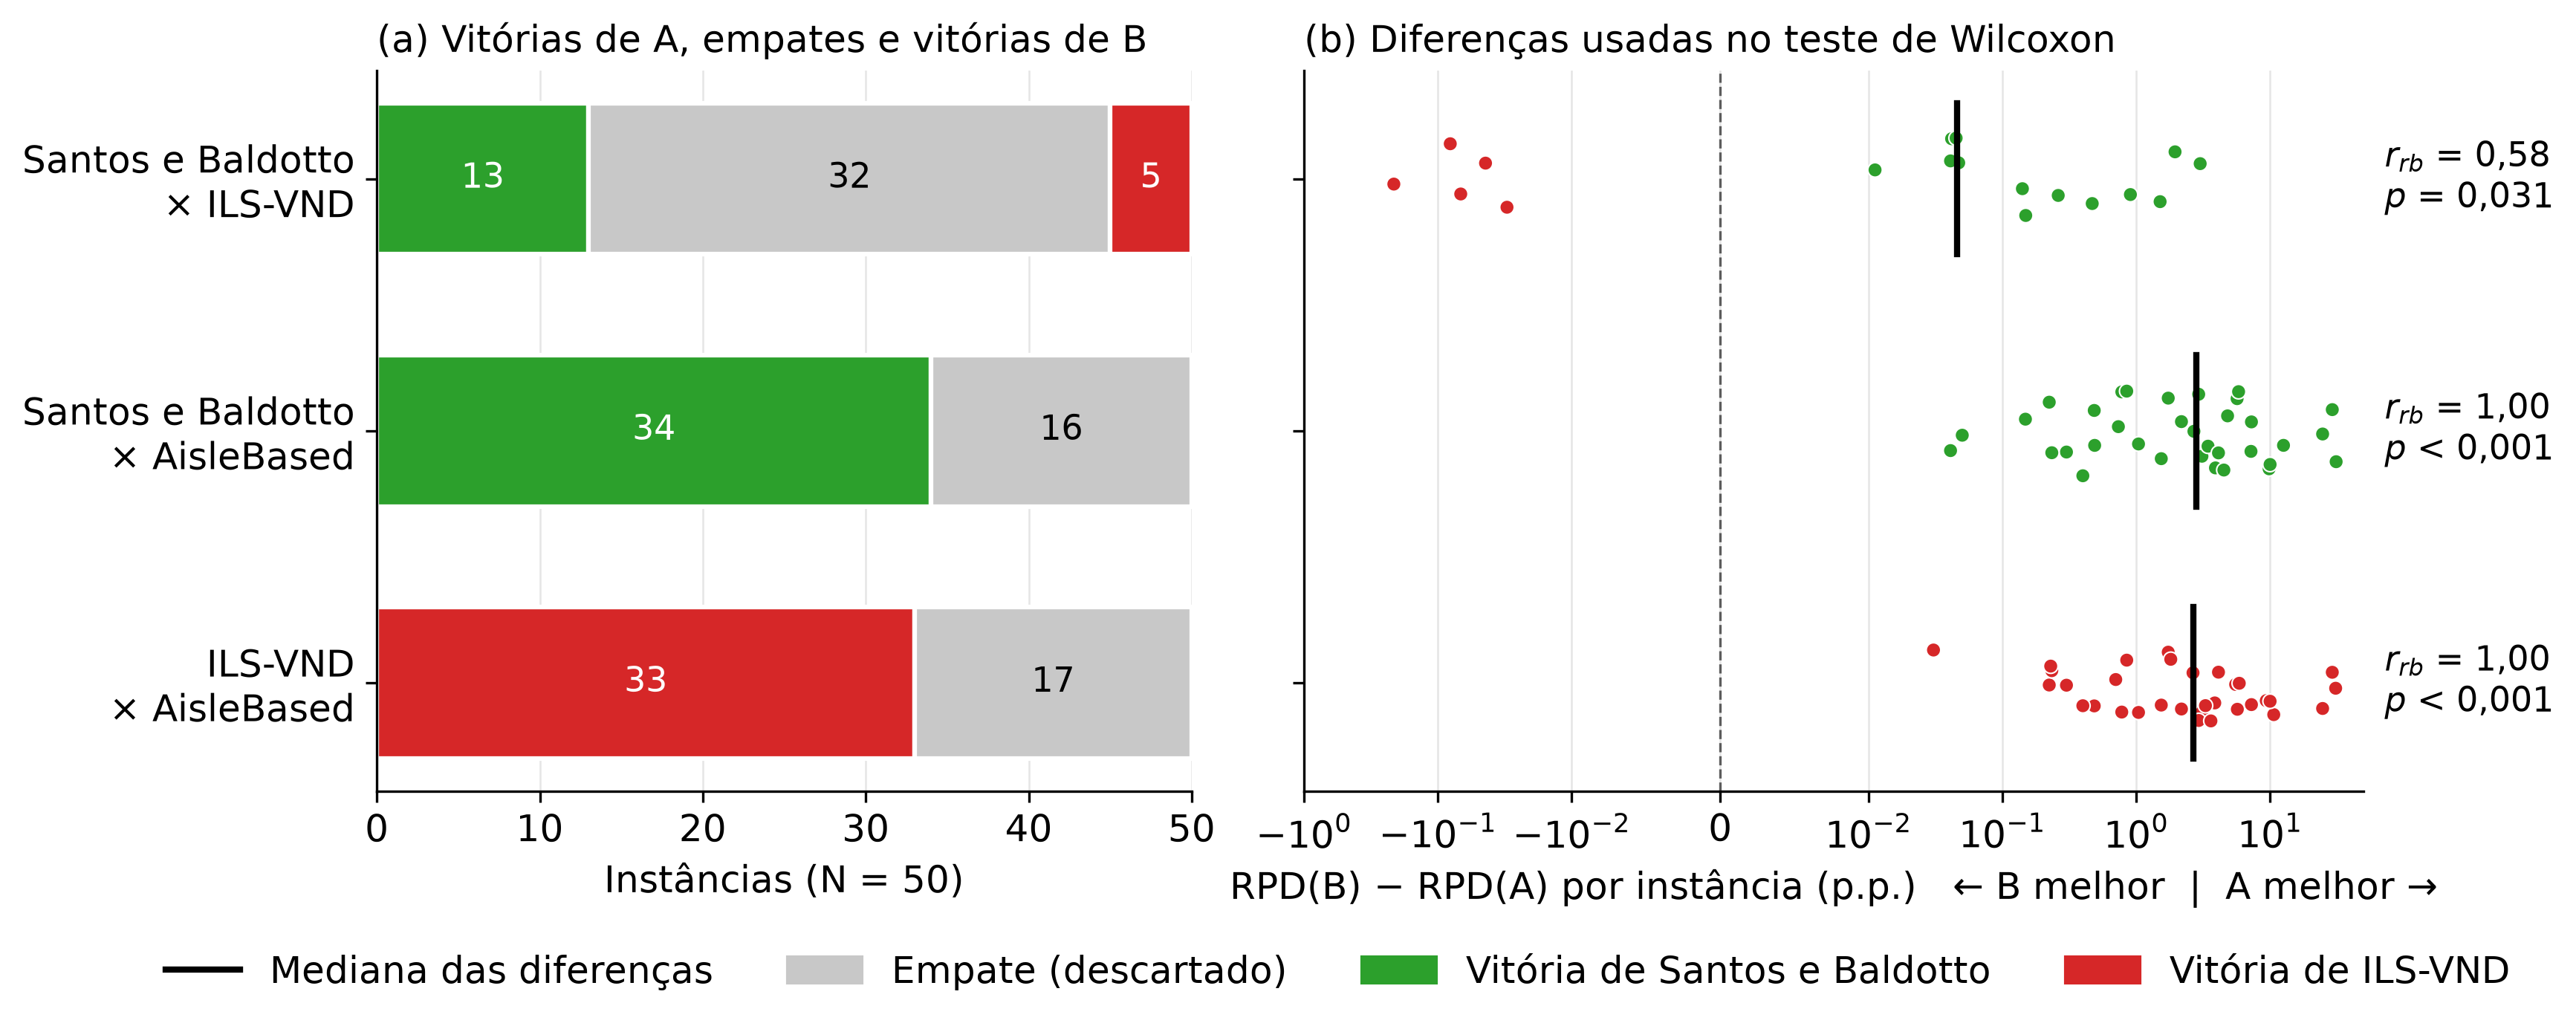

In [6]:
# --- Figura: representação visual da comparação par a par ---
# (a) vitórias / empates / derrotas por par (o que o teste de Wilcoxon descarta aparece em cinza);
# (b) diferença de RPD em cada instância com diferença (entrada do teste), escala symlog.
plt.rcParams.update({"font.size": 12})
fig, (axa, axb) = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True,
                               gridspec_kw={"width_ratios": [1.0, 1.3], "wspace": 0.12})
ypos = np.arange(len(tab))[::-1]
rng = np.random.default_rng(12345)
for y, (_, r) in zip(ypos, tab.iterrows()):
    emp = N - r.n_dif
    segs = [(r.vit_A, COR[r.A], "white"), (emp, "#c8c8c8", "black"), (r.vit_B, COR[r.B], "white")]
    x0 = 0
    for w, c, tc in segs:
        if w:
            axa.barh(y, w, left=x0, height=0.6, color=c, edgecolor="white", lw=1.5)
            if w >= 3:
                axa.text(x0 + w / 2, y, str(w), ha="center", va="center", color=tc, fontsize=11)
        x0 += w
    d = diferencas_rpd(r.A, r.B); d = d[d != 0]
    jit = rng.uniform(-0.18, 0.18, d.size)
    axb.scatter(d, y + jit, s=22, c=[COR[r.A] if v > 0 else COR[r.B] for v in d],
                edgecolor="white", lw=0.5, zorder=3)
    axb.plot([np.median(d)] * 2, [y - 0.3, y + 0.3], color="k", lw=2, zorder=4)
    sig = "" if r.p_holm < ALPHA else " (n.s.)"
    p_txt = "$p$ < 0,001" if r.p_holm < 1e-3 else f"$p$ = {num(r.p_holm, 3).replace('{,}', ',')}"
    axb.text(1.02, y, f"$r_{{rb}}$ = {num(r.r_rb).replace('{,}', ',')}\n{p_txt}{sig}",
             transform=axb.get_yaxis_transform(), va="center", fontsize=11)

rotulos = [f"{nome_curto(r.A)}\n× {nome_curto(r.B)}" for _, r in tab.iterrows()]
axa.set_yticks(ypos, rotulos)
axa.set_xlim(0, N); axa.set_xlabel(f"Instâncias (N = {N})")
axa.set_title("(a) Vitórias de A, empates e vitórias de B", fontsize=12, loc="left")
axb.axvline(0, color="k", lw=0.8, ls="--", alpha=0.6)
axb.set_xscale("symlog", linthresh=0.01)
_todas = np.concatenate([diferencas_rpd(a, b) for a, b in pares])
axb.set_xlim(-max(1.0, 1.6 * np.abs(_todas[_todas < 0]).max(initial=0)), 1.6 * _todas.max())
axb.set_xlabel("RPD(B) − RPD(A) por instância (p.p.)   ← B melhor  |  A melhor →")
axb.set_title("(b) Diferenças usadas no teste de Wilcoxon", fontsize=12, loc="left")
for ax in (axa, axb):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
leg = [Line2D([], [], color="k", lw=2, label="Mediana das diferenças"),
       plt.Rectangle((0, 0), 1, 1, color="#c8c8c8", label="Empate (descartado)")]
# só os algoritmos que vencem alguma comparação aparecem com cor na figura
vencedores = [a for a in ordem if ((tab.A == a) & (tab.vit_A > 0)).any() or ((tab.B == a) & (tab.vit_B > 0)).any()]
leg += [plt.Rectangle((0, 0), 1, 1, color=COR[a], label=f"Vitória de {nome_curto(a)}") for a in vencedores]
fig.legend(handles=leg, loc="lower center", ncol=len(leg), frameon=False, bbox_to_anchor=(0.5, -0.14))
for ext in ("pdf", "png"):
    fig.savefig(IMG / f"testes_estatisticos.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    if TEXTO_IMG.exists():
        fig.savefig(TEXTO_IMG / f"testes_estatisticos.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=str(IMG / "testes_estatisticos.png"), width=900))